# PACE OCI AO.emp vs. DBO in-situ chlorophyll match-ups

Validate **Lewis & Arrigo (2020) AO.emp** applied to **PACE OCI Rrs** against in-situ extracted
Chl-*a*, before wiring AO.emp into the weekly pipeline. Mirrors the MODIS AO.emp validation
(`2_figures/figS01_modis-chl-matchups.ipynb`) so the statistics are **directly
comparable** to that panel.

**In-situ (PACE-era only — the saved `insitu_surface_chl.csv` stops at 2023 and yields zero PACE
match-ups):**
| source | cruise | when | time stamp |
|---|---|---|---|
| Sikuliaq | `SKQ202412S` (`chla`, extracted) | Aug 2024 | date-only → whole UTC day |
| Mirai | `MR24-06C` (`CHLWEL`, Welschmeyer, WOCE flag 2) | Sep 2024 | DATE+TIME UTC |
| Mirai | `MR25-05C` (`CHLWEL`, Welschmeyer, WOCE flag 2) | Sep 2025 | DATE+TIME UTC |

**Satellite** = PACE OCI **L2 AOP** Rrs (`PACE_OCI_L2_AOP`, reprocessed standard — **not** `_NRT`,
which does not cover 2024). **Match-up protocol** = Bailey & Werdell (2006): shallowest bottle
nearest 5 m; 5×5 box on the nearest PACE pixel; OBPG `l2_flags` masking; > 50 % valid; 1.5 σ
filter; spatial-CV gate. **Time window = ±24 h** (Mirai use real cast time; Sikuliaq whole-day).

**Band-selection experiment.** AO.emp needs Rrs at the MODIS centres 443 / 488 / 547 nm. PACE is
hyperspectral, so we compute AO.emp **two ways** and quantify how much the choice matters:
- **A — nearest slice:** the native PACE band closest to each target.
- **B — 1-nm interpolation:** `rrs.interp(wavelength=arange(400,701))` then pick 443/488/547 —
  i.e. linearly interpolate the spectrum to the exact MODIS centres.

Part C reports the per-match-up Δlog₁₀ between A and B and its effect on R²/RMSE/bias/slope,
so we know whether band selection is a real error source relative to the ~0.4 log₁₀ RMSE.

---
**Running locally (VS Code).** Select the **`pace_chl_v2`** conda kernel (has xarray + h5netcdf +
earthaccess). It reads PACE granules **lazily over HTTPS** — only the small box per granule (~tens of
MB), never the full ~1 GB file — so there is no big download and no disk-fill. You need Earthdata
credentials in `~/.netrc`:
```
machine urs.earthdata.nasa.gov login YOUR_USERNAME password YOUR_PASSWORD
```
(`chmod 600 ~/.netrc`). The CSV paths auto-resolve to the repo copies; the config cell prints
`OK`/`MISSING` for each. First-run per-station lazy reads are minutes, cached and resumable.

In [20]:
import os, re, pickle, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import earthaccess
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 90)

## CONFIG — in-situ files, PACE product, Bailey & Werdell parameters, AO.emp + band methods

In [21]:
# ---- in-situ files: (path, source-label, loader-kind) --------------------------
# Edit these paths to point at the three CSVs (or drop them in cwd / $HOME).
def _first_existing(cands):
    for c in cands:
        if Path(c).exists(): return Path(c)
    return Path(cands[0])

SIKULIAQ = _first_existing([
    Path.home()/"ADD_YOUR_PATH"/"pace-functional-type"/"dbo-insitu"/"Sikuliaq2024_BottleData_v2.csv",  # add your path
    Path.cwd()/"Sikuliaq2024_BottleData_v2.csv", Path.home()/"Sikuliaq2024_BottleData_v2.csv"])  # add your path
MIRAI24 = _first_existing([
    Path.home()/"ADD_YOUR_PATH"/"japan"/"MR24060120241220031312.csv",  # add your path
    Path.cwd()/"MR24060120241220031312.csv", Path.home()/"MR24060120241220031312.csv"])  # add your path
MIRAI25 = _first_existing([
    Path.home()/"ADD_YOUR_PATH"/"japan"/"MR25050120251126002002.csv",  # add your path
    Path.cwd()/"MR25050120251126002002.csv", Path.home()/"MR25050120251126002002.csv"])  # add your path

INSITU_SOURCES = [
    (SIKULIAQ, "SKQ2024",  "sikuliaq"),
    (MIRAI24,  "MR24-06C", "mirai"),
    (MIRAI25,  "MR25-05C", "mirai"),
]

OUT_DIR       = Path.cwd() / "pace_aoemp_matchups"
GRANULE_CACHE = OUT_DIR / "granules"
OUT_DIR.mkdir(parents=True, exist_ok=True); GRANULE_CACHE.mkdir(parents=True, exist_ok=True)
for p, s, _ in INSITU_SOURCES:
    print(f"{s:9s} {'OK ' if p.exists() else 'MISSING'} {p}")

# ---- in-situ surface sampling (Bailey & Werdell) -------------------------------
TARGET_DEPTH_M = 5.0
MAX_SURFACE_DB = 10.0
CHL_MIN, CHL_MAX = 0.0, 100.0
MIRAI_CHL_COL   = "CHLWEL"          # extracted Welschmeyer chl-a (ug/L == mg m^-3)
MIRAI_GOOD_FLAG = {2}               # WOCE water-sample flag: 2 = acceptable
SENTINELS = [-999, -999.0, -99, -9, 1e-12]

# ---- PACE L2 AOP product -------------------------------------------------------
PACE_AOP_SHORT = "PACE_OCI_L2_AOP"  # standard/reprocessed. NRT will not cover 2024.

# ---- Bailey & Werdell (2006) match-up protocol ---------------------------------
# Relaxed from strict B&W for the sparse, cloudy Arctic (validation, not an operational
# product): a 3x3 box and ">=1 valid pixel" keep partly-cloudy scenes instead of dropping them.
BOX_SIZE          = 3              # 3x3 box (was 5x5)
TIME_WINDOW_HOURS = 24.0          # request: +/-24 h
MIN_VALID_FRAC    = 0.0           # keep the box if >=1 pixel is valid (was >50%)
FILTER_SIGMA      = 1.5
MAX_CV            = 0.5            # loosen the spatial-homogeneity gate (np.inf disables)
MAX_PIX_DIST_KM   = 4.0           # nearest pixel within 4 km (was 2)
BBOX_HALF_DEG     = 0.20
MAX_CANDIDATES    = 12
DAY_PAD_DAYS      = 0             # widen whole-day (date-only) search by +/- this many days
RECOMPUTE         = False

# ---- AO.emp (Lewis & Arrigo 2020, pan-Arctic; MODIS 443>488 / 547 centres) ------
AOEMP = dict(a=0.0957, b=-2.7973, c=0.6581)
RRS_TARGETS = (443.0, 488.0, 547.0)   # nm
WL_1NM = np.arange(400, 701)          # 1-nm grid for the interpolation method (Method B)

# ARCTIC-ADJUSTED mask: HISATZEN (high sat-zenith) and HISOLZEN (high solar-zenith) are DROPPED.
# PACE views the high-latitude DBO region at a steep angle, so HISATZEN fires on ~100% of in-box
# water; including it masks essentially everything (it silently thinned an earlier run to N=9).
# These are viewing-geometry conditions, not retrieval failures. Real quality flags are kept.
EXCLUDE_FLAGS = [
    "ATMFAIL", "LAND", "HIGLINT", "HILT", "STRAYLIGHT", "CLDICE",
    "COCCOLITH", "LOWLW", "CHLFAIL", "NAVWARN", "MAXAERITER",
    "CHLWARN", "NAVFAIL", "FILTER",
]

SKQ2024   OK  ~/ADD_YOUR_PATH/pace-functional-type/dbo-insitu/Sikuliaq2024_BottleData_v2.csv
MR24-06C  OK  ~/ADD_YOUR_PATH/japan/MR24060120241220031312.csv
MR25-05C  OK  ~/ADD_YOUR_PATH/japan/MR25050120251126002002.csv


## Part A — Build the in-situ surface Chl-*a* table (3 cruises)

One surface value per station-cast: the shallowest bottle nearest 5 m with `pressure <= 10 db`.
Sikuliaq (`chla`) is date-only → whole-day window. Mirai (`CHLWEL`, WOCE flag 2) carries
DATE+TIME → real ±24 h window.

In [22]:
def _num(s): return pd.to_numeric(s, errors="coerce")
def _mask_sent(s): return s.mask(s.isin(SENTINELS))

def _pick_surface(sub_df, keycols):
    # sub_df cols: station, cast, datetime, lat, lon, pressure_db, chl_insitu.
    # Return one shallowest-near-5 m row per group in keycols.
    recs = []
    for _, g in sub_df.groupby(keycols, dropna=True):
        d = g.dropna(subset=["pressure_db", "chl_insitu", "lat", "lon", "datetime"])
        d = d[(d["chl_insitu"] > CHL_MIN) & (d["chl_insitu"] <= CHL_MAX) & (d["pressure_db"] >= 0)]
        if d.empty: continue
        b = d.assign(dd=(d["pressure_db"] - TARGET_DEPTH_M).abs()).sort_values("dd").iloc[0]
        if b["pressure_db"] > MAX_SURFACE_DB: continue
        recs.append(b)
    return pd.DataFrame(recs)

def load_sikuliaq(path, source):
    df = pd.read_csv(path, low_memory=False); df.columns = [str(c).strip() for c in df.columns]
    dt = pd.to_datetime(df["DataDate"].astype(str).str.replace(r"\.0$", "", regex=True),
                        format="%Y%m%d", errors="coerce")
    base = pd.DataFrame({"station": df["StationNme"].astype(str), "cast": _num(df.get("Cast_Number")),
                         "datetime": dt, "lat": _num(df["Latitude"]), "lon": _num(df["Longitude"]),
                         "pressure_db": _mask_sent(_num(df["Pres_dbar"])),
                         "chl_insitu": _mask_sent(_num(df["chla"]))})
    s = _pick_surface(base, ["station", base["datetime"].dt.date])
    s["source"] = source; s["cruise"] = "SKQ202412S"; s["time_known"] = False   # date-only
    return s

def load_mirai(path, source):
    df = pd.read_csv(path, encoding="shift_jis", skiprows=[1, 2], low_memory=False)
    df.columns = [str(c).strip() for c in df.columns]
    st = df["Station"] if "Station" in df.columns else df["STNNBR"]
    prs  = _mask_sent(_num(df["CTDPRS"]))
    chl  = _mask_sent(_num(df[MIRAI_CHL_COL]))
    flag = _num(df.get(MIRAI_CHL_COL + "_FLAG_W"))
    chl  = chl.where(flag.isin(MIRAI_GOOD_FLAG))                # keep only acceptable-flagged chl
    dt = pd.to_datetime(df["DATE"].astype(str).str.strip() + " " + df["TIME"].astype(str).str.strip(),
                        format="%m/%d/%Y %H:%M", errors="coerce")
    base = pd.DataFrame({"station": st.astype(str).str.strip(), "cast": _num(df.get("CASTNO")),
                         "datetime": dt, "lat": _num(df["LATITUDE"]), "lon": _num(df["LONGITUDE"]),
                         "pressure_db": prs, "chl_insitu": chl})
    s = _pick_surface(base, ["station", "cast"])
    s["source"] = source; s["cruise"] = source; s["time_known"] = True          # real cast time
    return s

LOADERS = {"sikuliaq": load_sikuliaq, "mirai": load_mirai}
frames = []
for path, source, kind in INSITU_SOURCES:
    if not path.exists():
        print(f"  [skip] {source}: file missing"); continue
    f = LOADERS[kind](path, source)
    print(f"  {source:9s}: {len(f):3d} surface stations  ({f['datetime'].min().date()} -> {f['datetime'].max().date()})")
    frames.append(f)

insitu = pd.concat(frames, ignore_index=True)
insitu = insitu[["source", "cruise", "station", "datetime", "time_known",
                 "lat", "lon", "pressure_db", "chl_insitu"]].sort_values("datetime").reset_index(drop=True)
insitu["year"] = insitu["datetime"].dt.year
insitu["uid"]  = insitu["source"] + "_" + insitu.index.astype(str)
insitu.to_csv(OUT_DIR / "insitu_surface_chl_paceera.csv", index=False)
print(f"\nTOTAL {len(insitu)} surface stations | chl {insitu.chl_insitu.min():.2f}-{insitu.chl_insitu.max():.2f} "
      f"median {insitu.chl_insitu.median():.2f} mg m^-3")
insitu.groupby("source").agg(n=("chl_insitu", "size"), chl_med=("chl_insitu", "median")).round(3)

  SKQ2024  :  42 surface stations  (2024-08-08 -> 2024-08-25)
  MR24-06C :  37 surface stations  (2024-09-05 -> 2024-09-26)
  MR25-05C :  32 surface stations  (2025-09-04 -> 2025-09-22)

TOTAL 111 surface stations | chl 0.08-6.69 median 0.45 mg m^-3


,n,chl_med
source,,
MR24-06C,37,0.279
MR25-05C,32,0.366
SKQ2024,42,0.630


## Part B — PACE OCI L2 AOP match-ups (both band-selection methods at once)

Log in to Earthdata, confirm the AOP short name, then for each station find the nearest PACE
pixel, extract the 5×5 box across the **full** Rrs spectrum, and compute AO.emp **twice**:
nearest-slice (A) and 1-nm-interpolated (B).

In [24]:
auth = earthaccess.login(persist=True)
print("PACE AOP collections visible to your account:")
for c in earthaccess.search_datasets(keyword="PACE OCI L2 apparent optical properties"):
    sn = c["umm"]["ShortName"]
    if "AOP" in sn:
        print(f"  {sn:26s} | {c['umm'].get('EntryTitle','')}")

PACE AOP collections visible to your account:
  PACE_OCI_L2_AOP            | PACE OCI Level-2 Regional  Apparent Optical Properties Data, version 3.2
  PACE_OCI_L2_AOP_NRT        | PACE OCI Level-2 Regional  Apparent Optical Properties - Near Real-time (NRT) Data, version 3.2
  PACE_OCI_L3M_AOP           | PACE OCI Level-3 Global Mapped Apparent Optical Properties Data, version 3.2
  PACE_OCI_L3M_AOP_NRT       | PACE OCI Level-3 Global Mapped Apparent Optical Properties - Near Real-time (NRT) Data, version 3.2


In [25]:
# ---- machinery -----------------------------------------------------------------
def build_flag_bitmask(l2_flags_var, names):
    masks    = np.asarray(l2_flags_var.attrs["flag_masks"]).astype("int64")
    meanings = str(l2_flags_var.attrs["flag_meanings"]).split()
    name2mask = dict(zip(meanings, masks))
    bits = 0
    for n in names:
        if n in name2mask: bits |= int(name2mask[n])
    return bits

def haversine_km(lat1, lon1, lat2, lon2):
    R, p = 6371.0, np.pi / 180.0
    dlat, dlon = (lat2 - lat1) * p, (lon2 - lon1) * p
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def aoemp_chl(r443, r488, r547):
    r443, r488, r547 = (np.asarray(v, float) for v in (r443, r488, r547))
    R = np.log10(np.maximum(r443, r488) / r547)
    return 10 ** (AOEMP["a"] + AOEMP["b"] * R + AOEMP["c"] * R * R)

def _boxmean_aoemp(rrs3, valid):
    # rrs3: (n,n,3) Rrs at 443/488/547 for ONE band-selection method; valid: (n,n) flag-clean.
    r443, r488, r547 = rrs3[..., 0], rrs3[..., 1], rrs3[..., 2]
    v = valid & np.isfinite(r443) & np.isfinite(r488) & np.isfinite(r547) & (r547 > 0)
    n_box, n_valid = r443.size, int(v.sum())
    if n_valid <= MIN_VALID_FRAC * n_box:
        return {"status": "too_few_valid", "n_box": n_box, "n_valid": n_valid}
    chl = aoemp_chl(r443[v], r488[v], r547[v]); chl = chl[np.isfinite(chl) & (chl > 0)]
    if chl.size == 0:
        return {"status": "no_finite_aoemp", "n_box": n_box, "n_valid": n_valid}
    m0, s0 = float(chl.mean()), float(chl.std(ddof=0)); cv = s0 / m0 if m0 > 0 else np.inf
    keep = np.abs(chl - m0) <= FILTER_SIGMA * s0
    sat = float(chl[keep].mean()) if keep.any() else m0
    return {"status": "ok" if cv <= MAX_CV else "high_cv", "sat": sat, "cv": float(cv),
            "n_box": n_box, "n_valid": n_valid}

_WL_SEL = {"nearest": None}   # remembers the native PACE wavelengths chosen by Method A

def _open_grp(g, grp):
    # lazy handle — HTTPS byte-range (local) or direct S3 (in-region). Only requested
    # bytes are read, so we never pull the full ~1 GB granule for a 5x5 box.
    return xr.open_dataset(earthaccess.open([g])[0], group=grp, engine="h5netcdf")

def pace_matchup(g, lat0, lon0):
    geo = _open_grp(g, "geophysical_data")
    nav = _open_grp(g, "navigation_data")
    try:
        wl = _open_grp(g, "sensor_band_parameters")["wavelength_3d"].values.astype(float)
    except Exception:
        wl = geo["wavelength_3d"].values.astype(float)
    latg = nav["latitude"].values.astype("float64"); long = nav["longitude"].values.astype("float64")
    rrs = geo["Rrs"]; d0, d1 = rrs.dims[0], rrs.dims[1]

    near = (np.abs(latg - lat0) < 0.25) & (np.abs(long - lon0) < 0.5)
    if not near.any():
        geo.close(); nav.close(); return {"status": "not_in_swath"}
    ii, jj = np.where(near)
    dist = haversine_km(lat0, lon0, latg[ii, jj], long[ii, jj])
    k = int(np.argmin(dist)); i0, j0, dmin = int(ii[k]), int(jj[k]), float(dist[k])
    if dmin > MAX_PIX_DIST_KM:
        geo.close(); nav.close(); return {"status": "too_far", "dist_km": dmin}
    h = BOX_SIZE // 2
    if i0 - h < 0 or j0 - h < 0 or i0 + h >= latg.shape[0] or j0 + h >= latg.shape[1]:
        geo.close(); nav.close(); return {"status": "box_off_edge", "dist_km": dmin}

    sl = {d0: slice(i0 - h, i0 + h + 1), d1: slice(j0 - h, j0 + h + 1)}
    rrs_box = rrs.isel(**sl).values.astype("float64")            # (n, n, Nwl) — only the box loads
    fbox    = geo["l2_flags"].isel(**sl).values.astype("int64")
    fbits   = build_flag_bitmask(geo["l2_flags"], EXCLUDE_FLAGS)
    geo.close(); nav.close()
    valid = (fbox & fbits) == 0
    n = rrs_box.shape[0]

    # --- Method A: nearest native slice to each target ---
    idx = [int(np.argmin(np.abs(wl - t))) for t in RRS_TARGETS]
    _WL_SEL["nearest"] = [float(wl[i]) for i in idx]
    rrsA = rrs_box[..., idx]

    # --- Method B: 1-nm interpolation, then pick 443/488/547 (== interp straight to targets) ---
    rrsB = np.empty((n, n, 3), float)
    for a in range(n):
        for b in range(n):
            spec1nm = np.interp(WL_1NM, wl, rrs_box[a, b, :])   # your snippet: interp to 1-nm grid
            rrsB[a, b, :] = [spec1nm[int(np.argmin(np.abs(WL_1NM - t)))] for t in RRS_TARGETS]

    A = _boxmean_aoemp(rrsA, valid); B = _boxmean_aoemp(rrsB, valid)
    return {"status": A["status"], "status_interp": B["status"], "dist_km": dmin,
            "n_valid": A.get("n_valid"), "n_box": A.get("n_box"),
            "sat_nearest": A.get("sat"), "cv_nearest": A.get("cv"),
            "sat_interp": B.get("sat"),  "cv_interp": B.get("cv"),
            "wl_nearest": _WL_SEL["nearest"]}

def granule_mid_time(g):
    rt = g["umm"]["TemporalExtent"]["RangeDateTime"]
    a = pd.to_datetime(rt["BeginningDateTime"]).tz_localize(None)
    b = pd.to_datetime(rt["EndingDateTime"]).tz_localize(None)
    return a + (b - a) / 2

print("PACE dual-method AO.emp machinery ready")

PACE dual-method AO.emp machinery ready


In [26]:
# ---- main match-up loop (cached + resumable) -----------------------------------
CACHE_PKL = OUT_DIR / "matchup_cache_pace_aoemp.pkl"
cache = {} if (RECOMPUTE or not CACHE_PKL.exists()) else pickle.load(open(CACHE_PKL, "rb"))
cache = {u: r for u, r in cache.items()
         if not str(r.get("status", "")).startswith(("read_err", "search_err"))}

results = []
for n, row in enumerate(insitu.itertuples(index=False), 1):
    uid = row.uid
    if uid in cache: results.append(cache[uid]); continue
    lat0, lon0, t_is = row.lat, row.lon, row.datetime
    if row.time_known:
        t0, t1 = t_is - pd.Timedelta(hours=TIME_WINDOW_HOURS), t_is + pd.Timedelta(hours=TIME_WINDOW_HOURS)
    else:
        t0 = t_is.normalize() - pd.Timedelta(days=DAY_PAD_DAYS)
        t1 = t_is.normalize() + pd.Timedelta(days=1 + DAY_PAD_DAYS)

    rec = {"uid": uid, "source": row.source, "station": row.station, "datetime": t_is,
           "lat": lat0, "lon": lon0, "chl_insitu": row.chl_insitu, "time_known": row.time_known,
           "status": "no_granule", "sat_nearest": np.nan, "sat_interp": np.nan}
    try:
        grans = earthaccess.search_data(
            short_name=PACE_AOP_SHORT,
            temporal=(t0.strftime("%Y-%m-%dT%H:%M:%S"), t1.strftime("%Y-%m-%dT%H:%M:%S")),
            bounding_box=(lon0 - BBOX_HALF_DEG, lat0 - BBOX_HALF_DEG,
                          lon0 + BBOX_HALF_DEG, lat0 + BBOX_HALF_DEG))
    except Exception as e:
        grans = []; rec["status"] = f"search_err:{str(e)[:50]}"

    if grans:
        grans = sorted(grans, key=lambda g: abs((granule_mid_time(g) - t_is).total_seconds()))[:MAX_CANDIDATES]
        best, fallback = None, None
        for g in grans:
            gt = granule_mid_time(g); dt_h = (gt - t_is).total_seconds() / 3600.0
            if row.time_known and abs(dt_h) > TIME_WINDOW_HOURS: continue
            try:
                m = pace_matchup(g, lat0, lon0)              # lazy: reads only the 5x5 box
            except Exception as e:
                m = {"status": f"read_err:{str(e)[:50]}"}
            cand = {**m, "dt_hours": dt_h, "granule": g["umm"]["GranuleUR"], "sat_time": gt}
            if cand["status"] == "ok":
                if best is None or abs(dt_h) < abs(best["dt_hours"]): best = cand
            elif fallback is None:
                fallback = cand
        if best is not None: rec.update(best)
        elif fallback is not None:
            rec.update({k: fallback.get(k) for k in
                        ("status", "dt_hours", "granule", "cv_nearest", "n_valid", "n_box", "dist_km")})

    cache[uid] = rec; results.append(rec)
    if n % 5 == 0 or n == len(insitu):
        pickle.dump(cache, open(CACHE_PKL, "wb"))
        nok = sum(1 for r in results if r.get("status") == "ok")
        print(f"  {n}/{len(insitu)} stations — {nok} match-ups so far")
pickle.dump(cache, open(CACHE_PKL, "wb"))
if _WL_SEL["nearest"]:
    print("Nearest PACE wavelengths for (443,488,547):", [round(w, 2) for w in _WL_SEL["nearest"]])

QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3002.37it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:02<00:00,  2.24s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 17331.83it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 5295.84it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.71s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 16710.37it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3452.10it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.62s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 14463.12it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3625.15it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:06<00:00,  6.61s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 16710.37it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 4739.33it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.62s/it]
COLLECTING RESULTS | : 100%|██████████| 1/

  100/111 stations — 11 match-ups so far


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 1754.94it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.55s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 32263.88it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3949.44it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.58s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 24966.10it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3344.74it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.47s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 20763.88it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 2809.31it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.67s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 15363.75it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3297.41it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.65s/it]
COLLECTING RESULTS | : 100%|██████████| 1/

  105/111 stations — 11 match-ups so far


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3236.35it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.77s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 15141.89it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 5683.34it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.34s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 17772.47it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3019.66it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.60s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 15650.39it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3276.80it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.57s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 15363.75it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 5683.34it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.50s/it]
COLLECTING RESULTS | : 100%|██████████| 1/

  110/111 stations — 11 match-ups so far


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 4583.94it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.58s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 17331.83it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 4443.12it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.68s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 17476.27it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3533.53it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.69s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 7695.97it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 2531.26it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.61s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 12633.45it/s]
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3672.77it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.66s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1

  111/111 stations — 11 match-ups so far
Nearest PACE wavelengths for (443,488,547): [442.0, 487.0, 547.0]


In [27]:
# ---- assemble + save -----------------------------------------------------------
mdf = pd.DataFrame(results)
matched = mdf[(mdf["status"] == "ok") & np.isfinite(mdf.get("sat_nearest")) &
              np.isfinite(mdf.get("sat_interp"))].copy()
mdf.to_csv(OUT_DIR / "pace_aoemp_matchups_all_attempts.csv", index=False)
matched.to_csv(OUT_DIR / "pace_aoemp_matchups.csv", index=False)

print("Outcome of every station:"); print(mdf["status"].value_counts(), "\n")
print(f"{len(matched)} valid AO.emp match-ups out of {len(mdf)} stations")
print("\nMatch-ups by source:")
print(matched.groupby("source").agg(n=("sat_nearest", "size"),
                                    insitu_med=("chl_insitu", "median"),
                                    pace_med=("sat_interp", "median")).round(3))
matched[["source", "station", "datetime", "chl_insitu", "sat_nearest", "sat_interp",
         "cv_nearest", "dt_hours", "dist_km"]].round(3).head(30)

Outcome of every station:
status
too_few_valid    90
ok               11
too_far           8
not_in_swath      1
no_granule        1
Name: count, dtype: int64 

11 valid AO.emp match-ups out of 111 stations

Match-ups by source:
          n  insitu_med  pace_med
source                           
MR25-05C  6       0.428     0.570
SKQ2024   5       1.530     1.462


,source,station,datetime,chl_insitu,sat_nearest,sat_interp,cv_nearest,dt_hours,dist_km
10,SKQ2024,UTBS1,2024-08-12 00:00:00,5.940,3.821,3.967,0.184,20.975,0.891
11,SKQ2024,DBO2.7,2024-08-12 00:00:00,0.650,0.739,0.749,0.045,20.975,2.340
12,SKQ2024,PA1,2024-08-12 00:00:00,1.270,1.867,1.860,0.056,20.975,1.680
23,SKQ2024,IC5 [IC7],2024-08-16 00:00:00,1.710,0.683,0.677,0.162,0.338,0.882
34,SKQ2024,BarC3,2024-08-20 00:00:00,1.530,1.448,1.462,0.000,19.099,0.591
82,MR25-05C,4,2025-09-04 23:18:00,1.602,1.284,1.307,0.108,21.870,1.073
83,MR25-05C,5,2025-09-05 04:06:00,0.435,0.776,0.803,0.321,18.709,0.096
87,MR25-05C,9,2025-09-06 04:28:00,0.914,1.222,1.239,0.120,17.288,0.423
88,MR25-05C,10,2025-09-06 08:05:00,0.367,0.265,0.277,0.086,13.671,0.508
91,MR25-05C,13,2025-09-06 19:44:00,0.356,0.243,0.252,0.000,2.021,0.332


## Part C — Validation statistics + band-selection uncertainty

Log₁₀-space validation (N, R², RMSE, bias, RMA slope — the MODIS recipe verbatim). Then the
**band-method experiment**: per-match-up Δlog₁₀ = log₁₀(chl_interp) − log₁₀(chl_nearest), its
spread, and the two methods' stats side by side — so we can say how much uncertainty the band
choice adds relative to the ~0.4 log₁₀ retrieval RMSE.

In [28]:
def validation_stats(insitu_v, sat_v):
    insitu_v, sat_v = np.asarray(insitu_v, float), np.asarray(sat_v, float)
    m = np.isfinite(insitu_v) & np.isfinite(sat_v) & (insitu_v > 0) & (sat_v > 0)
    x, y = np.log10(insitu_v[m]), np.log10(sat_v[m]); n = len(x)
    if n < 3: return {"N": n}
    r = np.corrcoef(x, y)[0, 1]; sx, sy = x.std(ddof=1), y.std(ddof=1)
    slope = np.sign(np.cov(x, y)[0, 1]) * sy / sx
    intercept = y.mean() - slope * x.mean()
    return {"N": n, "R2": r ** 2,
            "RMSE_log10": float(np.sqrt(np.mean((y - x) ** 2))),
            "bias_log10": float(np.mean(y - x)),
            "MAE_log10":  float(np.mean(np.abs(y - x))),
            "RMA_slope": float(slope), "RMA_intercept": float(intercept),
            "MdAPD_pct": float(np.median(np.abs(sat_v[m] - insitu_v[m]) / insitu_v[m]) * 100),
            "median_ratio": float(np.median(sat_v[m] / insitu_v[m]))}

st_near = validation_stats(matched["chl_insitu"], matched["sat_nearest"])
st_int  = validation_stats(matched["chl_insitu"], matched["sat_interp"])
comp = pd.DataFrame({"nearest slice": st_near, "1-nm interp": st_int}).T
print("PACE AO.emp validation — nearest slice vs 1-nm interpolation:\n")
print(comp.round(4).to_string())

PACE AO.emp validation — nearest slice vs 1-nm interpolation:

                  N      R2  RMSE_log10  bias_log10  MAE_log10  RMA_slope  RMA_intercept  MdAPD_pct  median_ratio
nearest slice  11.0  0.7673      0.1837     -0.0461     0.1553     0.9815        -0.0467    31.6860        0.8113
1-nm interp    11.0  0.7655      0.1828     -0.0392     0.1530     0.9806        -0.0398    29.3263        0.8157


saved ~/ADD_YOUR_PATH/lewis-arrigo/pace_aoemp_matchups/pace_aoemp_validation_scatter.png


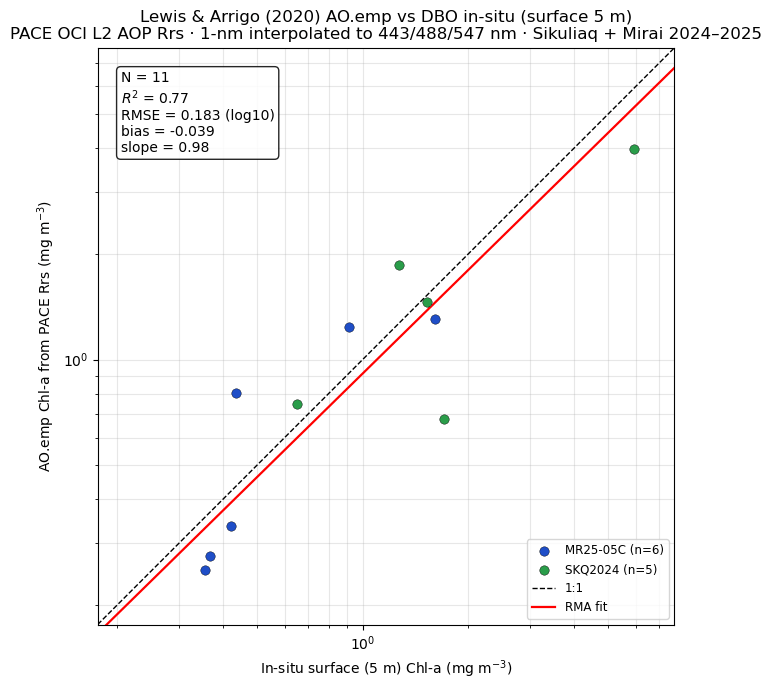

In [30]:
# ---- primary 1:1 scatter (log-log) with RMA fit — matches the MODIS AO.emp panel (Fig. S1)
COL = {"SKQ2024": "#2a9d4a", "MR24-06C": "#d6602c", "MR25-05C": "#1f4ec7"}
PRIMARY = "sat_interp"          # 1-nm interpolation hits the exact MODIS centres
stats_all = validation_stats(matched["chl_insitu"], matched[PRIMARY])

fig, ax = plt.subplots(figsize=(7, 7))
for src, g in matched.groupby("source"):
    ax.scatter(g["chl_insitu"], g[PRIMARY], s=46, color=COL.get(src, "#2a9d4a"),
               edgecolor="k", linewidth=.3, zorder=3, label=f"{src} (n={len(g)})")

lo = max(1e-2, min(matched["chl_insitu"].min(), matched[PRIMARY].min()) * 0.7)
hi = max(matched["chl_insitu"].max(), matched[PRIMARY].max()) * 1.3
xx = np.array([lo, hi])
ax.plot(xx, xx, "k--", lw=1, label="1:1", zorder=2)
if stats_all.get("N", 0) >= 3:
    s, b = stats_all["RMA_slope"], stats_all["RMA_intercept"]
    ax.plot(xx, 10 ** b * xx ** s, "r-", lw=1.6, label="RMA fit", zorder=2)
    ax.text(0.04, 0.96,
            f"N = {stats_all['N']}\n$R^2$ = {stats_all['R2']:.2f}\n"
            f"RMSE = {stats_all['RMSE_log10']:.3f} (log10)\n"
            f"bias = {stats_all['bias_log10']:+.3f}\nslope = {stats_all['RMA_slope']:.2f}",
            transform=ax.transAxes, va="top", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))

wl = _WL_SEL.get("nearest")
sub = "1-nm interpolated to 443/488/547 nm" if PRIMARY == "sat_interp" else \
      (f"nearest slices {wl[0]:.0f}/{wl[1]:.0f}/{wl[2]:.0f} nm" if wl else "nearest slices")
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi), aspect="equal",
       xlabel="In-situ surface (5 m) Chl-a (mg m$^{-3}$)",
       ylabel="AO.emp Chl-a from PACE Rrs (mg m$^{-3}$)",
       title="Lewis & Arrigo (2020) AO.emp vs DBO in-situ (surface 5 m)\n"
             f"PACE OCI L2 AOP Rrs · {sub} · Sikuliaq + Mirai 2024–2025")
ax.legend(fontsize=8.5, loc="lower right"); ax.grid(alpha=.3, which="both")
plt.tight_layout()
fig.savefig(OUT_DIR / "pace_aoemp_validation_scatter.png", dpi=150,
            metadata={"Title": "PACE AO.emp vs DBO in-situ (Sikuliaq + Mirai 2024-2025)",
                      "Software": "figS01_pace-chl-matchups.ipynb"})
print("saved", OUT_DIR / "pace_aoemp_validation_scatter.png")

### Notes & caveats

- **In-situ chl are not identical measurements.** Sikuliaq `chla` and Mirai `CHLWEL` are both
  *extracted* chl-a but by different labs/methods (Welschmeyer non-acidification on Mirai). Cross-
  cruise offsets are possible; the per-source colours in the scatter let you see if one cruise sits
  off the RMA line. Mirai chl are filtered to WOCE flag 2 (acceptable) only.
- **Band-selection uncertainty (Part C) is the deliverable you asked for.** If the Δlog₁₀ spread is
  a few thousandths — small vs the ~0.4 retrieval RMSE — nearest-slice is fine and the interpolation
  is a negligible refinement. If it is not small, prefer the interpolated bands (they hit the exact
  MODIS centres the coefficients were fit to). The printout states the % of RMSE explicitly.
- **Residual band-shift.** Even the interpolated Rrs are sampled at MODIS *centres* but through
  PACE's ~5 nm bandpass, not MODIS's ~10 nm — a separate, smaller effect the ratio largely cancels.
- **±24 h.** Mirai use real cast time; Sikuliaq (date-only) uses the whole UTC day (≤ 24 h). Set
  `DAY_PAD_DAYS = 1` to widen if too few survive cloud QC.
- **Standard vs NRT.** Validation uses `PACE_OCI_L2_AOP`; the weekly pipeline uses `_NRT`. MR25-05C
  (Sep 2025) is recent enough that you *could* additionally validate the NRT Rrs there.
- **Comparability.** `validation_stats` and the figure are the MODIS recipe verbatim, so the numbers
  sit on the same axes as your MODIS AO.emp panel (N=48, R²=0.49, RMSE=0.395).